# Étude des variables - SmartMed

Objectif : comprendre quelles variables influencent chaque module IA.


In [42]:
import pandas as pd
import matplotlib.pyplot as plt

doctors = pd.read_csv("data/clean/doctors_clean.csv")
reviews = pd.read_csv("data/clean/reviews_clean.csv")
waiting = pd.read_csv("data/clean/waiting_history_clean.csv")

print("doctors :", doctors.shape)
print("reviews :", reviews.shape)
print("waiting :", waiting.shape)

doctors : (50, 10)
reviews : (1168, 5)
waiting : (3950, 8)


In [43]:
waiting.info()
print(waiting.describe())
print(waiting.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 3950 entries, 0 to 3949
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   record_id             3950 non-null   int64  
 1   doctor_id             3950 non-null   int64  
 2   patients_before       3950 non-null   int64  
 3   avg_consultation_min  3950 non-null   int64  
 4   hour_of_day           3950 non-null   int64  
 5   day_of_week           3950 non-null   int64  
 6   actual_wait_min       3950 non-null   float64
 7   doctor_avg_delay_min  3950 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 247.0 KB
         record_id    doctor_id  patients_before  avg_consultation_min  \
count  3950.000000  3950.000000      3950.000000           3950.000000   
mean   1998.076203    25.470380         6.026582             24.138228   
std    1154.172273    14.424224         3.769042              9.615875   
min       1.000000     1.000000         0.00000

## Module attente

Question : qu'est-ce qui fait varier le temps d'attente réel ?


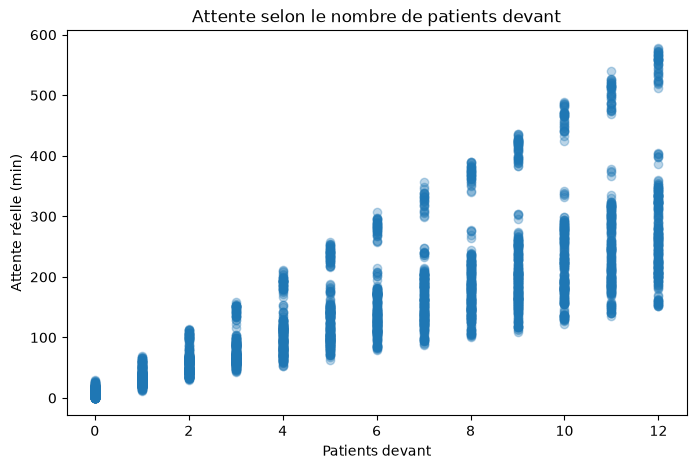

In [44]:
plt.figure(figsize=(8, 5))
plt.scatter(waiting["patients_before"], waiting["actual_wait_min"], alpha=0.3)
plt.xlabel("Patients devant")
plt.ylabel("Attente réelle (min)")
plt.title("Attente selon le nombre de patients devant")
plt.show()

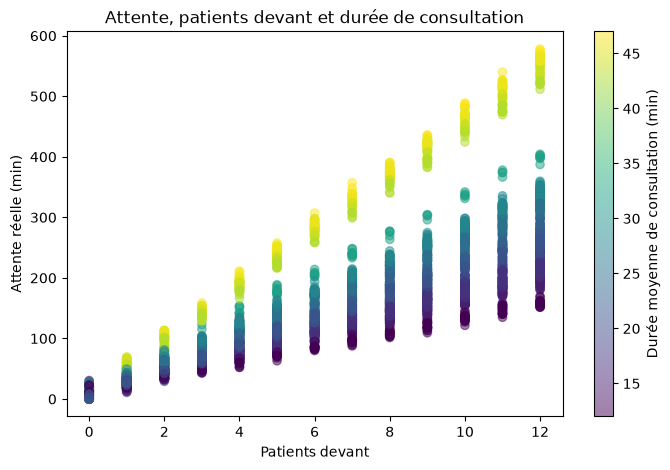

In [45]:
plt.figure(figsize=(8, 5))
points = plt.scatter(
    waiting["patients_before"],
    waiting["actual_wait_min"],
    c=waiting["avg_consultation_min"],
    cmap="viridis",
    alpha=0.5,
)
plt.colorbar(points, label="Durée moyenne de consultation (min)")
plt.xlabel("Patients devant")
plt.ylabel("Attente réelle (min)")
plt.title("Attente, patients devant et durée de consultation")
plt.show()

count    3950.000000
mean      155.778278
std       112.654750
min         0.000000
25%        67.325000
50%       140.400000
75%       211.350000
max       578.100000
Name: actual_wait_min, dtype: float64
Part des attentes de plus de 2 h : 57 %


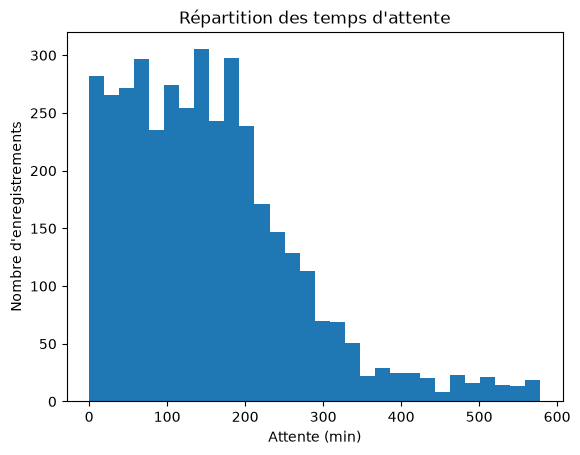

In [46]:
print(waiting["actual_wait_min"].describe())
print("Part des attentes de plus de 2 h :", round((waiting["actual_wait_min"] > 120).mean() * 100), "%")

waiting["actual_wait_min"].plot(kind="hist", bins=30)
plt.title("Répartition des temps d'attente")
plt.xlabel("Attente (min)")
plt.ylabel("Nombre d'enregistrements")
plt.show()

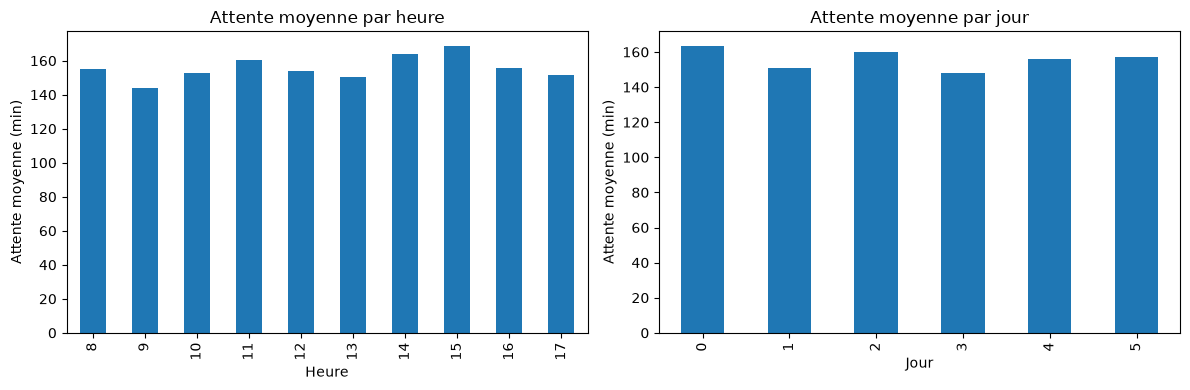

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

waiting.groupby("hour_of_day")["actual_wait_min"].mean().plot(kind="bar", ax=axes[0])
axes[0].set_title("Attente moyenne par heure")
axes[0].set_xlabel("Heure")
axes[0].set_ylabel("Attente moyenne (min)")

waiting.groupby("day_of_week")["actual_wait_min"].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Attente moyenne par jour")
axes[1].set_xlabel("Jour")
axes[1].set_ylabel("Attente moyenne (min)")

plt.tight_layout()
plt.show()

actual_wait_min         1.000000
patients_before         0.795455
avg_consultation_min    0.507542
doctor_avg_delay_min    0.026508
hour_of_day             0.020649
day_of_week            -0.012647
Name: actual_wait_min, dtype: float64


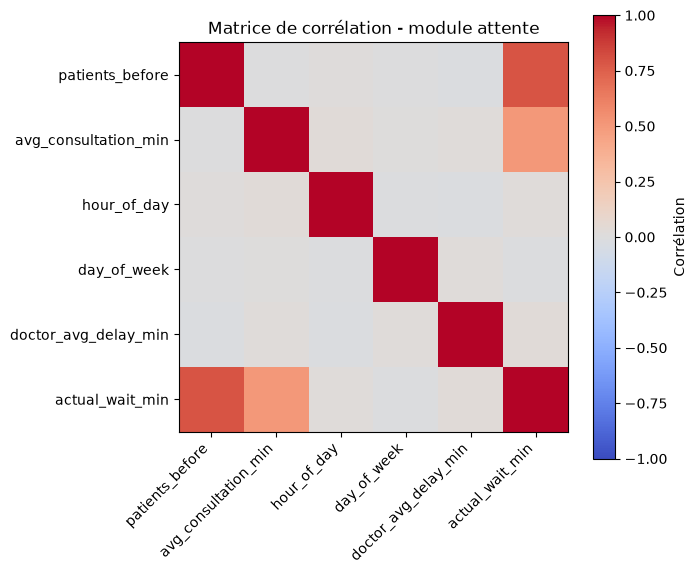

In [48]:
cols = ["patients_before", "avg_consultation_min", "hour_of_day",
        "day_of_week", "doctor_avg_delay_min", "actual_wait_min"]

corr = waiting[cols].corr()
print(corr["actual_wait_min"].sort_values(ascending=False))

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Corrélation")
plt.xticks(range(len(cols)), cols, rotation=45, ha="right")
plt.yticks(range(len(cols)), cols)
plt.title("Matrice de corrélation - module attente")
plt.tight_layout()
plt.show()

### Conclusion - module attente

- **`patients_before`** est la variable la plus liée à l'attente (corrélation de 0,80) : plus il y a de patients devant, plus l'attente est longue.
- **`avg_consultation_min`** vient ensuite (0,51) et amplifie le précédent : à nombre de patients égal, les médecins aux consultations longues ont une attente bien plus élevée. L'attente dépend donc du produit des deux.
- **`doctor_avg_delay_min` (0,03), `hour_of_day` (0,02) et `day_of_week` (-0,01)** ont une corrélation proche de 0 avec l'attente, et l'attente moyenne par heure ou par jour varie peu (environ 145 à 170 min). Leur effet est faible dans ces données.
- Les variables d'entrée ne sont pas corrélées entre elles : aucune n'est redondante.
- Les attentes simulées sont **longues** (moyenne de 156 min, et 57 % dépassent 2 h) : la simulation représente une file sans rendez-vous, avec jusqu'à 12 patients devant soi.
- `doctor_avg_delay_min` est calculée à partir de l'attente réelle, y compris celle que le modèle devra prédire : au Sprint 6, il faudra la recalculer uniquement sur les données d'entraînement (fuite de données).
- Pour le modèle (Sprint 6) : garder `patients_before` et `avg_consultation_min`, et tester une variable combinée `patients_before × avg_consultation_min`. Les trois autres variables seront conservées pour comparaison, sans gros gain attendu.


## Module sentiment

Question : le sentiment d'un avis est-il lié à sa note, et les classes sont-elles équilibrées ?


sentiment
positive    652
neutral     347
negative    169
Name: count, dtype: int64
               mean  min  max
sentiment                    
negative   1.834320    1    2
neutral    3.000000    3    3
positive   4.411043    4    5


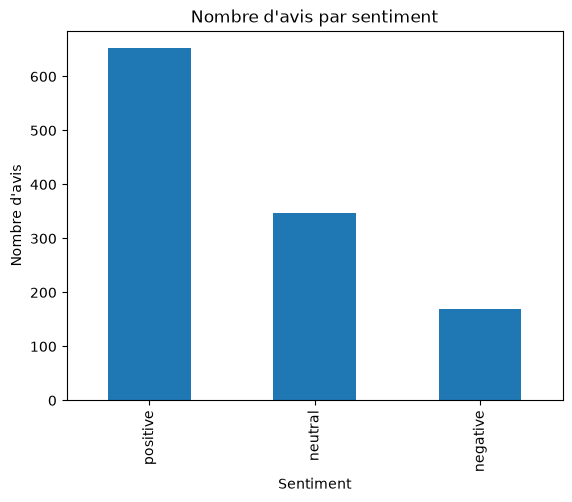

In [49]:
counts = reviews["sentiment"].value_counts()
print(counts)
print(reviews.groupby("sentiment")["rating"].agg(["mean", "min", "max"]))

counts.plot(kind="bar")
plt.title("Nombre d'avis par sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Nombre d'avis")
plt.show()

### Conclusion - module sentiment

- Les classes sont **déséquilibrées** : 652 avis positifs (56 %), 347 neutres (30 %) et 169 négatifs (14 %). Un modèle qui répondrait toujours « positif » aurait déjà environ 56 % de bonnes réponses : il faudra évaluer avec des métriques par classe (précision et rappel de chaque sentiment) et éventuellement rééquilibrer les données au Sprint 6.
- Le sentiment est **entièrement déterminé par la note** dans ces données : négatif = notes de 1 à 2 (moyenne 1,83), neutre = exactement 3, positif = notes de 4 à 5 (moyenne 4,41). Les intervalles ne se chevauchent pas.
- Conséquence : la note ne doit pas servir d'entrée au modèle, sinon il n'apprendrait rien du texte. Le modèle devra classer à partir du **commentaire seul**, et la note servira à vérifier ses résultats.


## Module recommandation

Question : les variables des médecins sont-elles assez variées pour les classer, et sont-elles redondantes entre elles ?


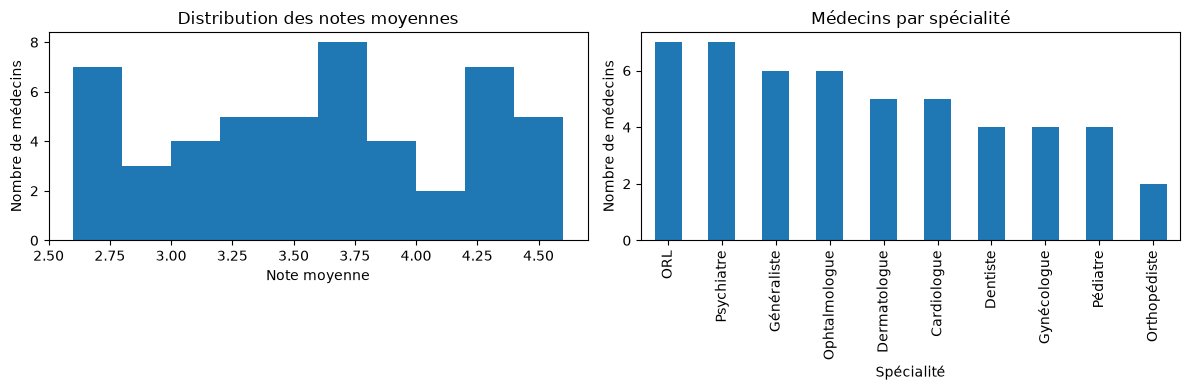

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

doctors["avg_rating"].plot(kind="hist", bins=10, ax=axes[0])
axes[0].set_title("Distribution des notes moyennes")
axes[0].set_xlabel("Note moyenne")
axes[0].set_ylabel("Nombre de médecins")

doctors["specialty"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("Médecins par spécialité")
axes[1].set_xlabel("Spécialité")
axes[1].set_ylabel("Nombre de médecins")

plt.tight_layout()
plt.show()

Note / attente moyenne : -0.18026826142190952
Note / nombre d'avis   : 0.18482800858662407


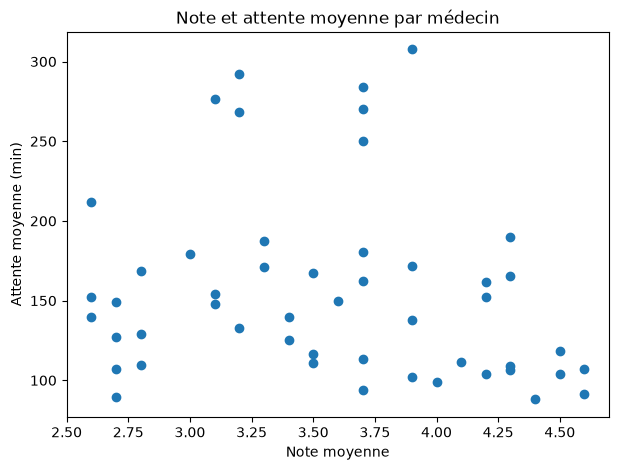

In [51]:
print("Note / attente moyenne :", doctors["avg_rating"].corr(doctors["avg_wait_minutes"]))
print("Note / nombre d'avis   :", doctors["avg_rating"].corr(doctors["reviews_count"]))

plt.figure(figsize=(7, 5))
plt.scatter(doctors["avg_rating"], doctors["avg_wait_minutes"])
plt.xlabel("Note moyenne")
plt.ylabel("Attente moyenne (min)")
plt.title("Note et attente moyenne par médecin")
plt.show()

### Conclusion - module recommandation

- Les notes moyennes sont bien étalées (environ 2,6 à 4,6) : `avg_rating` permet de distinguer les médecins.
- Il y a 10 spécialités avec seulement 2 à 7 médecins chacune : une fois filtré par spécialité et par distance, le patient aura peu de choix, et le classement portera sur peu de médecins.
- `avg_rating` et `reviews_count` sont peu corrélés (0,18) : ils apportent chacun une information distincte.
- `avg_rating` et `avg_wait_minutes` ont une corrélation de -0,18, faible, qui peut venir du hasard avec seulement 50 médecins. Dans nos données simulées, la note est tirée indépendamment de l'attente : il n'y a pas de lien net, et les deux variables peuvent être utilisées ensemble dans le score. Ce lien devra être vérifié sur de vraies données.
- Limite : `reviews_count` va de 5 à 40 avis selon le médecin (médiane 25). La note moyenne d'un médecin à 5 avis est beaucoup moins fiable que celle d'un médecin à 40 : il faudra en tenir compte dans le score (par exemple avec une note lissée).
